In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the dataset (make sure the file name matches exactly what you downloaded)
df = pd.read_csv('Life Expectancy Data.csv')
# Kaggle datasets often have spaces at the start/end of column names, which causes errors.
df.columns = df.columns.str.strip()

# we are going to see the first 5 data
df.head()


,Country,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,...,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
0,Afghanistan,2015,Developing,65.0,263.0,62,0.01,71.279624,65.0,1154,...,6.0,8.16,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1
1,Afghanistan,2014,Developing,59.9,271.0,64,0.01,73.523582,62.0,492,...,58.0,8.18,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0
2,Afghanistan,2013,Developing,59.9,268.0,66,0.01,73.219243,64.0,430,...,62.0,8.13,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9
3,Afghanistan,2012,Developing,59.5,272.0,69,0.01,78.184215,67.0,2787,...,67.0,8.52,67.0,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8
4,Afghanistan,2011,Developing,59.2,275.0,71,0.01,7.097109,68.0,3013,...,68.0,7.87,68.0,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5


In [3]:
print(f"Shape: {df.shape}")

Shape: (2938, 22)


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2938 entries, 0 to 2937
Data columns (total 22 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Country                          2938 non-null   object 
 1   Year                             2938 non-null   int64  
 2   Status                           2938 non-null   object 
 3   Life expectancy                  2928 non-null   float64
 4   Adult Mortality                  2928 non-null   float64
 5   infant deaths                    2938 non-null   int64  
 6   Alcohol                          2744 non-null   float64
 7   percentage expenditure           2938 non-null   float64
 8   Hepatitis B                      2385 non-null   float64
 9   Measles                          2938 non-null   int64  
 10  BMI                              2904 non-null   float64
 11  under-five deaths                2938 non-null   int64  
 12  Polio               

In [9]:
# Drop rows where the target 'Life expectancy' is missing
df.dropna(subset=['Life expectancy'], inplace=True)

print(df['Life expectancy'].isnull().sum())

0


In [10]:
# Map 'Developed' to 1 and 'Developing' to 0
df['Status'] = df['Status'].map({'Developed': 1, 'Developing': 0})

# Check to make sure there are no NaNs left in this column
print(df['Status'].isnull().sum()) # Should print 0

0


In [12]:
# List the columns we want to impute
cols_to_impute = ['GDP', 'Population', 'Alcohol', 'Hepatitis B', 'BMI', 'Polio', 
                  'Total expenditure', 'Diphtheria', 'thinness  1-19 years', 
                  'thinness 5-9 years', 'Income composition of resources', 'Schooling']

# Fill missing values with the median of that specific country
for col in cols_to_impute:
    df[col] = df.groupby('Country')[col].transform(lambda x: x.fillna(x.median()))

# If any countries STILL have NaNs (because they had NO data for that column at all), 
# fill the rest with the overall dataset median.
for col in cols_to_impute:
    df[col] = df[col].fillna(df[col].median())

In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2928 entries, 0 to 2937
Data columns (total 22 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Country                          2928 non-null   object 
 1   Year                             2928 non-null   int64  
 2   Status                           2928 non-null   int64  
 3   Life expectancy                  2928 non-null   float64
 4   Adult Mortality                  2928 non-null   float64
 5   infant deaths                    2928 non-null   int64  
 6   Alcohol                          2928 non-null   float64
 7   percentage expenditure           2928 non-null   float64
 8   Hepatitis B                      2928 non-null   float64
 9   Measles                          2928 non-null   int64  
 10  BMI                              2928 non-null   float64
 11  under-five deaths                2928 non-null   int64  
 12  Polio                    

In [14]:
df.drop('Country', axis=1, inplace=True)
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2928 entries, 0 to 2937
Data columns (total 21 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Year                             2928 non-null   int64  
 1   Status                           2928 non-null   int64  
 2   Life expectancy                  2928 non-null   float64
 3   Adult Mortality                  2928 non-null   float64
 4   infant deaths                    2928 non-null   int64  
 5   Alcohol                          2928 non-null   float64
 6   percentage expenditure           2928 non-null   float64
 7   Hepatitis B                      2928 non-null   float64
 8   Measles                          2928 non-null   int64  
 9   BMI                              2928 non-null   float64
 10  under-five deaths                2928 non-null   int64  
 11  Polio                            2928 non-null   float64
 12  Total expenditure        

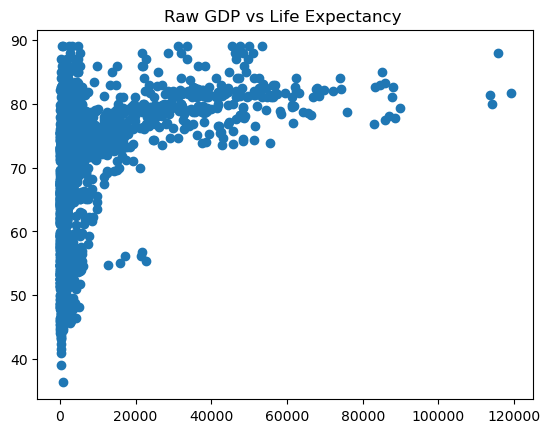

In [16]:
# 1. Plot raw GDP vs Life Expectancy
plt.scatter(df['GDP'], df['Life expectancy'])
plt.title("Raw GDP vs Life Expectancy ")
plt.show()

In [17]:
# 1. Create new columns with the log transformation
# We use np.log1p(x), which calculates log(1 + x). 
# This is safer than np.log(x) because log(0) is an error, but log1p(0) = 0.
df.head()
df['Log_GDP'] = np.log1p(df['GDP'])
df['Log_Population'] = np.log1p(df['Population'])
df['Log_percentage_expenditure'] = np.log1p(df['percentage expenditure'])

# 2. Drop the original massive columns because we now have the log versions
df.drop(['GDP', 'Population', 'percentage expenditure'], axis=1, inplace=True)

# 3. Look at the first few rows to make sure it worked
df.head()

,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,Hepatitis B,Measles,BMI,under-five deaths,...,Total expenditure,Diphtheria,HIV/AIDS,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling,Log_GDP,Log_Population,Log_percentage_expenditure
0,2015,0,65.0,263.0,62,0.01,65.0,1154,19.1,83,...,8.16,65.0,0.1,17.2,17.3,0.479,10.1,6.372055,17.334091,4.280542
1,2014,0,59.9,271.0,64,0.01,62.0,492,18.6,86,...,8.18,62.0,0.1,17.5,17.5,0.476,10.0,6.419501,12.699497,4.311116
2,2013,0,59.9,268.0,66,0.01,64.0,430,18.1,89,...,8.13,64.0,0.1,17.7,17.7,0.470,9.9,6.450067,17.272826,4.307023
3,2012,0,59.5,272.0,69,0.01,67.0,2787,17.6,93,...,8.52,67.0,0.1,17.9,18.0,0.463,9.8,6.508708,15.123021,4.371777
4,2011,0,59.2,275.0,71,0.01,68.0,3013,17.2,97,...,7.87,68.0,0.1,18.2,18.2,0.454,9.5,4.167242,14.906964,2.091507


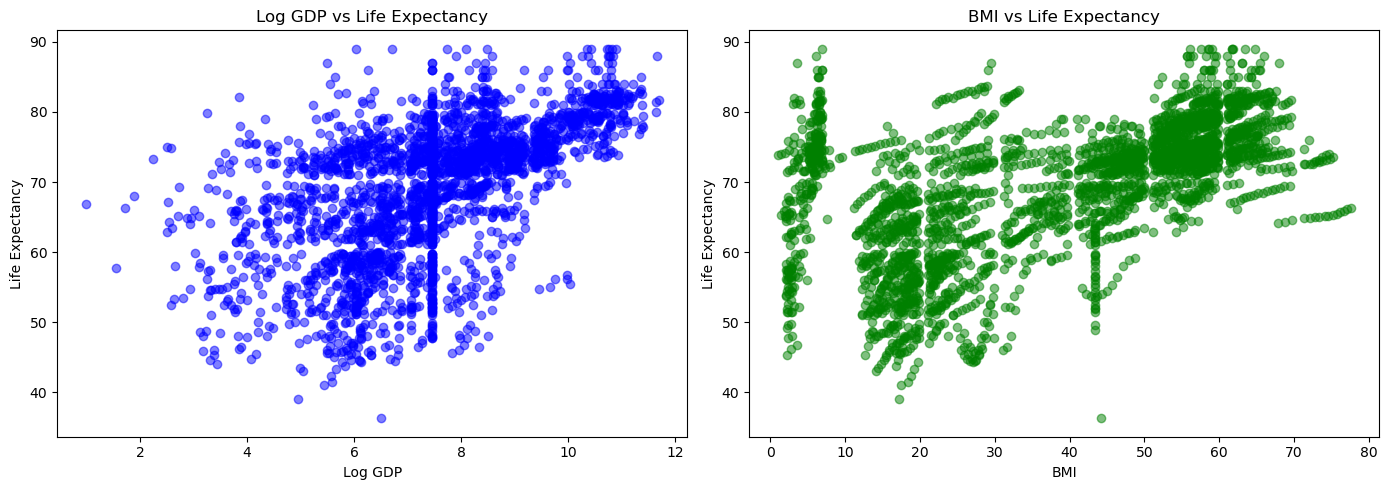

In [19]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Raw GDP vs Life Expectancy
# (We are plotting the original df before we dropped the column, so we have to recreate it briefly for the plot)
# Actually, since we already dropped it, let's just plot the Log version vs the Target
axes[0].scatter(df['Log_GDP'], df['Life expectancy'], alpha=0.5, color='blue')
axes[0].set_title('Log GDP vs Life Expectancy')
axes[0].set_xlabel('Log GDP')
axes[0].set_ylabel('Life Expectancy')

# Plot 2: Let's look at another feature, like BMI
axes[1].scatter(df['BMI'], df['Life expectancy'], alpha=0.5, color='green')
axes[1].set_title('BMI vs Life Expectancy')
axes[1].set_xlabel('BMI')
axes[1].set_ylabel('Life Expectancy')

plt.tight_layout()
plt.show()

In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2928 entries, 0 to 2937
Data columns (total 21 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Year                             2928 non-null   int64  
 1   Status                           2928 non-null   int64  
 2   Life expectancy                  2928 non-null   float64
 3   Adult Mortality                  2928 non-null   float64
 4   infant deaths                    2928 non-null   int64  
 5   Alcohol                          2928 non-null   float64
 6   Hepatitis B                      2928 non-null   float64
 7   Measles                          2928 non-null   int64  
 8   BMI                              2928 non-null   float64
 9   under-five deaths                2928 non-null   int64  
 10  Polio                            2928 non-null   float64
 11  Total expenditure                2928 non-null   float64
 12  Diphtheria               

In [21]:
from sklearn.model_selection import train_test_split

# 1. Create X and y
X = df.drop('Life expectancy', axis=1).values
y = df['Life expectancy'].values

# 2. Create X_train, X_test, y_train, y_test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 3. Define the function
def z_score_normalize(X_train, X_test):
    mu = np.mean(X_train, axis=0)
    sigma = np.std(X_train, axis=0)
    X_train_norm = (X_train - mu) / sigma
    X_test_norm = (X_test - mu) / sigma
    return X_train_norm, X_test_norm

# 4. Call the function to create X_train_norm
X_train_norm, X_test_norm = z_score_normalize(X_train, X_test)

In [22]:
print("X_train_norm mean (should be ~0):", np.mean(X_train_norm, axis=0).round(2))
print("X_train_norm std (should be 1):", np.std(X_train_norm, axis=0).round(2))

X_train_norm mean (should be ~0): [ 0.  0.  0.  0. -0.  0. -0.  0. -0.  0. -0.  0.  0. -0.  0.  0.  0. -0.
  0.  0.]
X_train_norm std (should be 1): [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [23]:
import copy
import math
# --- 1. The Cost Function ---
def compute_cost(X, y, w, b):
    m = X.shape[0]
    cost = 0.0
    for i in range(m):
        f_wb_i = np.dot(X[i], w) + b
        cost = cost + (f_wb_i - y[i])**2
    cost = cost / (2 * m)
    return cost

# --- 2. The Gradient Function ---
def compute_gradient(X, y, w, b):
    m, n = X.shape
    dj_dw = np.zeros((n,))
    dj_db = 0.
    
    for i in range(m):
        err = (np.dot(X[i], w) + b) - y[i]
        for j in range(n):
            dj_dw[j] = dj_dw[j] + err * X[i, j]
        dj_db = dj_db + err
        
    dj_dw = dj_dw / m
    dj_db = dj_db / m
    
    return dj_db, dj_dw

# --- 3. Gradient Descent ---
def gradient_descent(X, y, w_in, b_in, cost_function, gradient_function, alpha, num_iters):
    J_history = []
    w = copy.deepcopy(w_in)  # avoid modifying global w within function
    b = b_in
    
    for i in range(num_iters):
        # Calculate the gradient and update the parameters
        dj_db, dj_dw = gradient_function(X, y, w, b)   
        
        # Update Parameters using w, b, alpha and gradient
        w = w - alpha * dj_dw               
        b = b - alpha * dj_db               
      
        # Save cost J at each iteration
        if i<100000:      # prevent resource exhaustion 
            J_history.append( cost_function(X, y, w, b))

        # Print cost every at intervals 10 times or as many iterations if < 10
        if i % math.ceil(num_iters / 10) == 0:
            print(f"Iteration {i:4d}: Cost {J_history[-1]:8.2f}   ")
        
    return w, b, J_history #return final w,b and J history for graphing

In [24]:
# 1. Initialize parameters
n = X_train_norm.shape[1]   # number of features (should be 19)
initial_w = np.zeros(n)
initial_b = 0.

# 2. Set hyperparameters
iterations = 1000
alpha = 0.01 

# 3. Run Gradient Descent
print("Starting gradient descent...")
w_final, b_final, J_hist = gradient_descent(X_train_norm, y_train, initial_w, initial_b, 
                                            compute_cost, compute_gradient, 
                                            alpha, iterations)

print(f"\nFinished! Final w: {w_final}")
print(f"Final b: {b_final:.2f}")

Starting gradient descent...
Iteration    0: Cost  2385.38   
Iteration  100: Cost   323.05   
Iteration  200: Cost    50.70   
Iteration  300: Cost    14.20   
Iteration  400: Cost     9.30   
Iteration  500: Cost     8.63   
Iteration  600: Cost     8.54   
Iteration  700: Cost     8.52   
Iteration  800: Cost     8.51   
Iteration  900: Cost     8.51   

Finished! Final w: [-0.00973419  0.58373469 -2.52588104  0.38259815  0.14339829 -0.14211568
 -0.41610212  0.80005059 -0.40266199  0.74321043  0.1547045   0.99965082
 -2.544409   -0.41764521  0.06530512  1.23697652  1.86901899  0.82941487
 -0.28541483  0.25501043]
Final b: 69.15


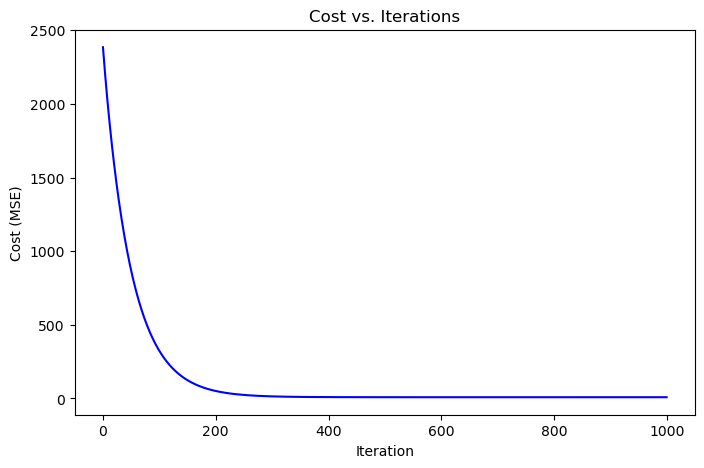

In [25]:
# Plot the cost history
fig, ax = plt.subplots(1, 1, figsize=(8, 5))
ax.plot(J_hist, color='blue')
ax.set_title("Cost vs. Iterations")
ax.set_xlabel("Iteration")
ax.set_ylabel("Cost (MSE)")
plt.show()

In [26]:
# 1. Make predictions on the test set
m_test = X_test_norm.shape[0]
predictions = np.zeros(m_test)

for i in range(m_test):
    predictions[i] = np.dot(X_test_norm[i], w_final) + b_final

# 2. Calculate Mean Squared Error (MSE)
mse = np.mean((predictions - y_test)**2)
print(f"Test Set MSE: {mse:.2f}")

# 3. Calculate R-squared (R2)
# R2 tells you what percentage of the variance in Life Expectancy is explained by your model.
ss_res = np.sum((y_test - predictions)**2)
ss_tot = np.sum((y_test - np.mean(y_test))**2)
r2 = 1 - (ss_res / ss_tot)
print(f"Test Set R-squared: {r2:.4f}")

Test Set MSE: 16.50
Test Set R-squared: 0.8093
